In [1]:
import pandas as pd
import matplotlib.pyplot as plt

normal = pd.read_csv("../data/SKAB/data/anomaly-free/anomaly-free.csv",
                     sep=";", index_col="datetime", parse_dates=True)
test = pd.read_csv("../data/SKAB/data/valve1/0.csv",
                   sep=";", index_col="datetime", parse_dates=True)

print("Normal shape:", normal.shape)
print("Columns:", normal.columns.tolist())
print(test["anomaly"].value_counts())
normal.head()

Normal shape: (9405, 8)
Columns: ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS']
anomaly
0.0    746
1.0    401
Name: count, dtype: int64


,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS
datetime,,,,,,,,
2020-02-08 13:30:47,0.202394,0.275154,2.16975,0.382638,90.6454,26.8508,238.852,122.664
2020-02-08 13:30:48,0.203153,0.277857,2.07999,-0.273216,90.7978,26.8639,227.943,122.338
2020-02-08 13:30:50,0.202054,0.275790,2.52577,0.382638,90.7730,26.8603,223.486,121.338
2020-02-08 13:30:51,0.203595,0.278101,2.49742,0.054711,90.8424,26.8616,244.904,121.664
2020-02-08 13:30:52,0.201889,0.276363,2.29194,0.710565,90.6664,26.8603,239.196,122.000


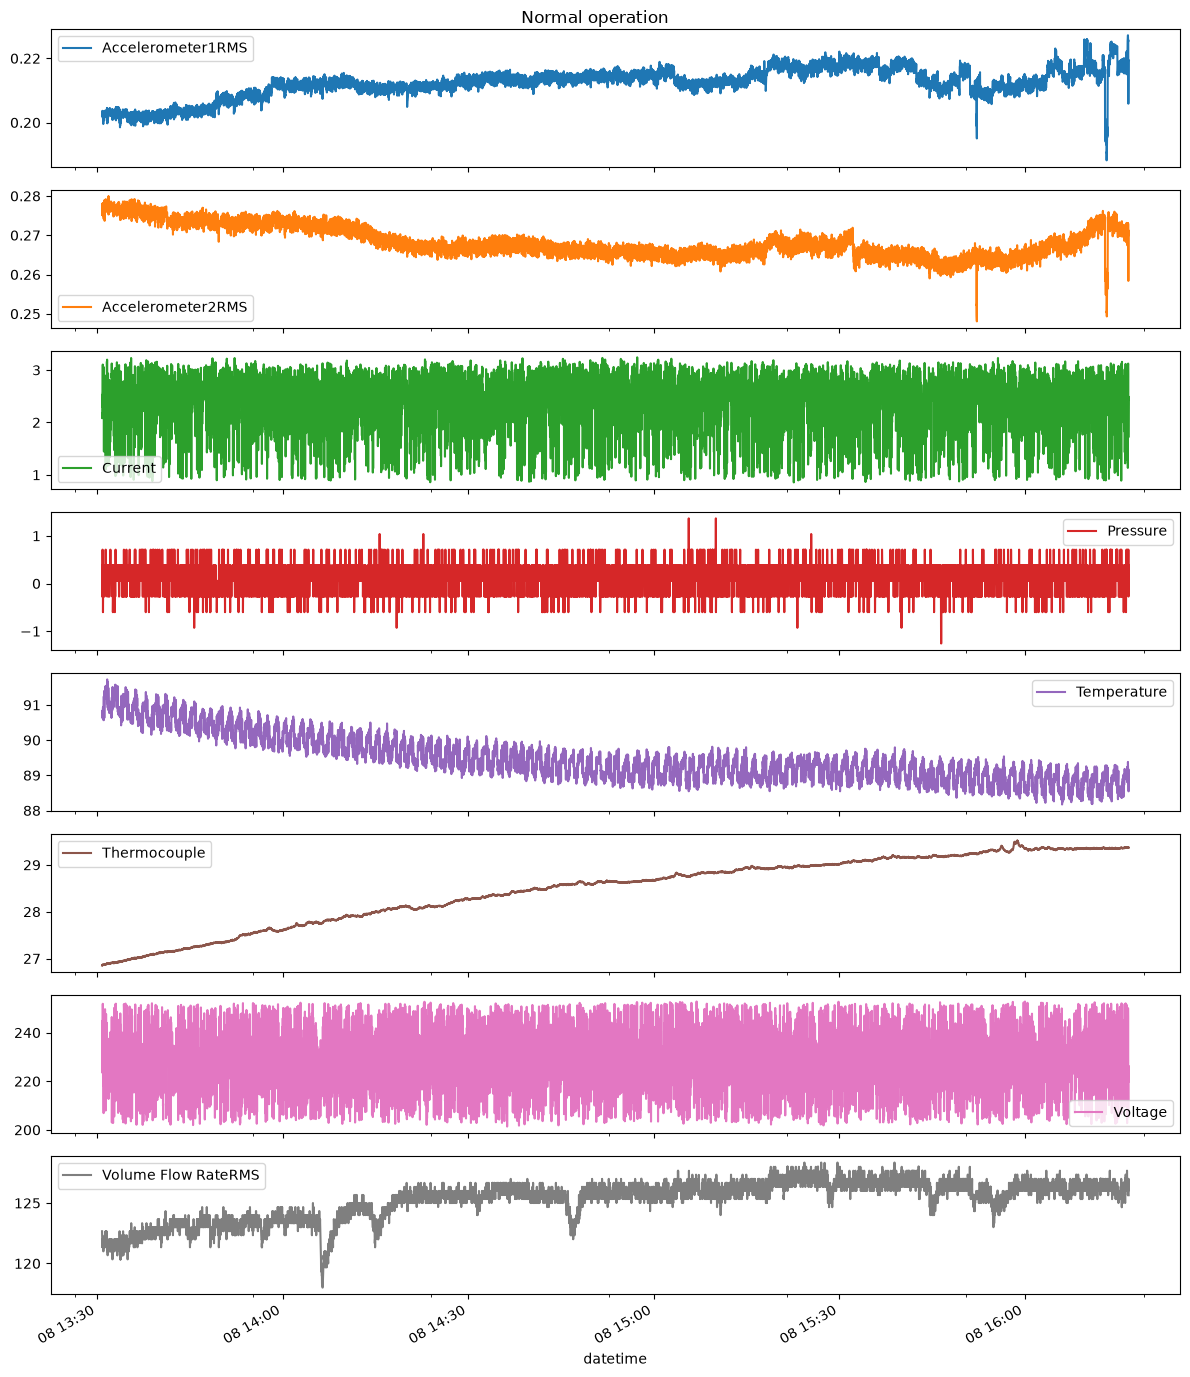

In [2]:
normal.plot(subplots=True, figsize=(12, 14), title="Normal operation")
plt.tight_layout()
plt.show()

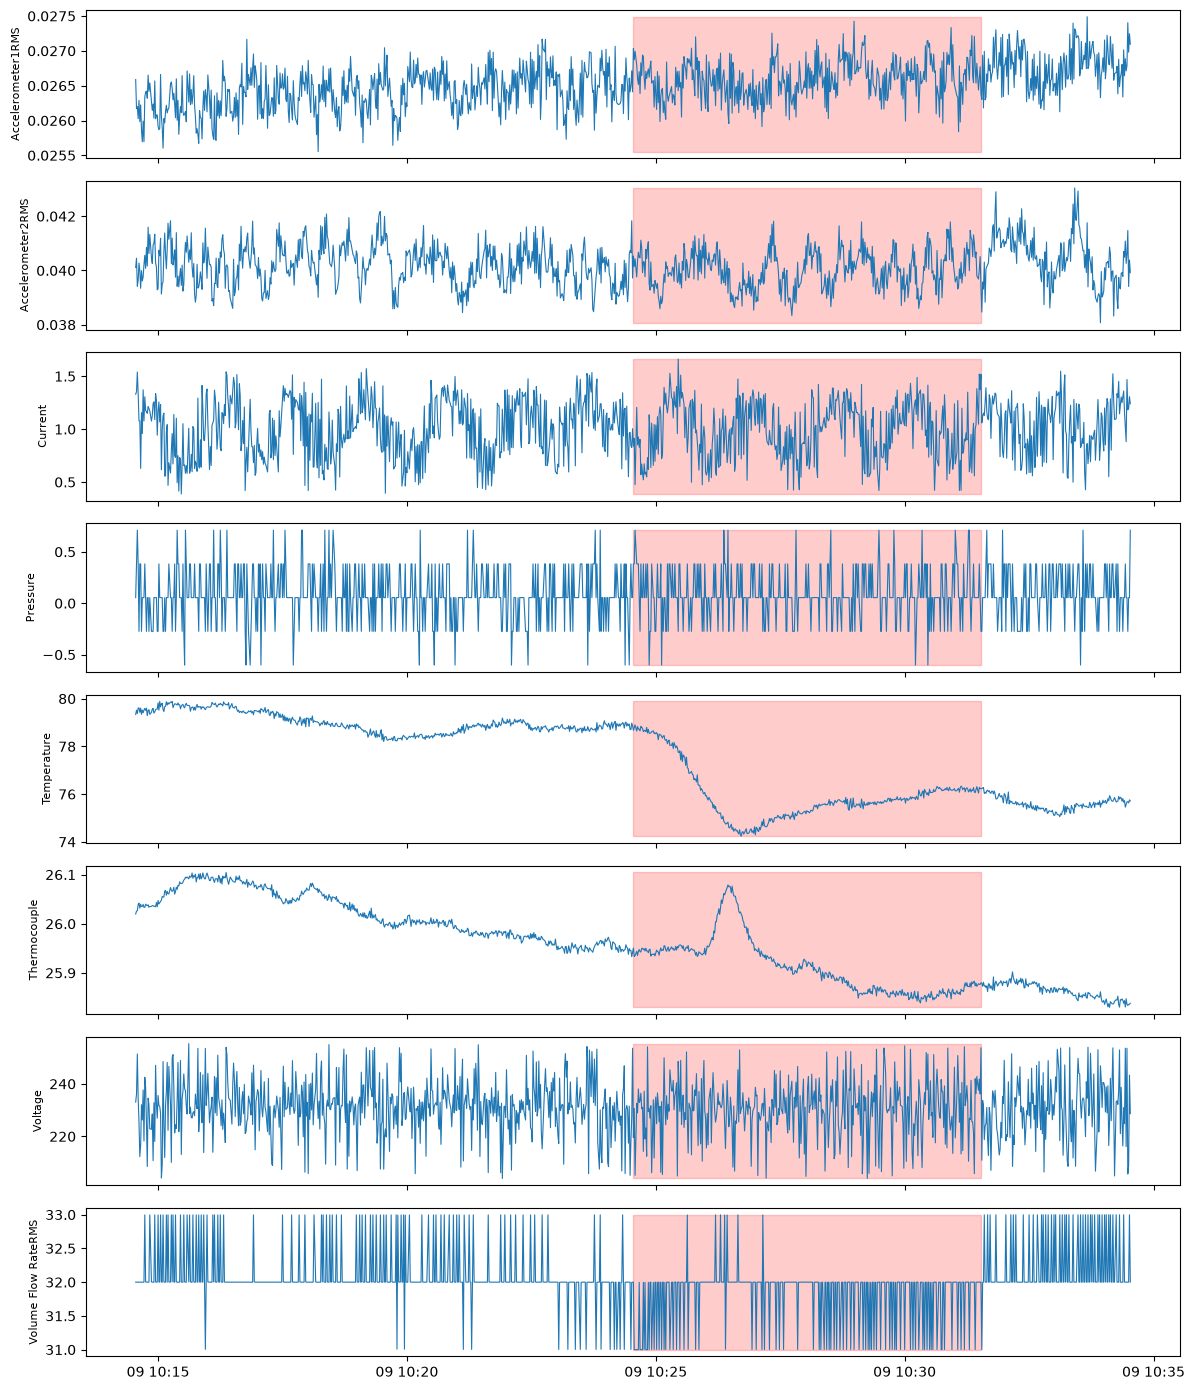

In [3]:
features = [c for c in test.columns if c not in ("anomaly", "changepoint")]
fig, axes = plt.subplots(len(features), 1, figsize=(12, 14), sharex=True)
for ax, col in zip(axes, features):
    ax.plot(test.index, test[col], lw=0.8)
    ax.fill_between(test.index, test[col].min(), test[col].max(),
                    where=test["anomaly"] == 1, color="red", alpha=0.2)
    ax.set_ylabel(col, fontsize=8)
plt.tight_layout()
plt.show()